# Corrected shared ALiBi: measured progress and qualification

One parameter set serves 12, 48, 108, and 192 spins. The guide fixes a
bond-defined canonical cell origin (averaging ties), guaranteeing consistency
under joint translations of spins and bonds. At h=0 it mixes probabilities of
s and −s, with consistent sampling and amplitude ratios. The base ALiBi decoder
also receives bond-weighted fields from earlier cells and a local-energy logit
prior. These inputs are causal. This model is not claimed to enforce rotations
or reflections, and canonicalization is discontinuous in bond inputs.

Training uses sampled physical VMC, all four sizes before each optimizer step,
258 disorder IDs per size, and three field pairs. No exact ground-state labels
enter training. Full enumeration at 12 spins supplies deterministic diagnostics;
larger-size measurements have sampling uncertainty and do not establish exact
ground-state accuracy.

This report distinguishes fixed validation curves from noisy changing-context
training energies. IDs 0 and 1 are training samples; 2–9 are retrospective
held-out samples; 10000–10001 are validation. The manifest records the test IDs
(20000–20007 for the pilot, 30000–30007 for the first main run). Once used to guide another experiment, inspected
test samples become development data and require a new confirmatory test set.


In [1]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
RESULTS=Path('/Users/tianyiyan/Dropbox/spin-glasses/data/kagome/transformer_af_shared_symmetric_v2_main')
status=json.loads((RESULTS/'status.json').read_text())
manifest=json.loads((RESULTS/'campaign.json').read_text())
display(Markdown('**Recorded status:** `'+str(status)+'`'))
display(Markdown(f"**Training schedule:** {manifest['steps']} updates, batch {manifest['batch']} per size; seed {manifest['seed']}."))
display(Markdown('**Reserved final-test IDs:** `'+str(manifest['final_test_ids'])+'`'))
validations=[json.loads(p.read_text()) for p in sorted(RESULTS.glob('validation_*.json'))]
evaluation=json.loads((RESULTS/'evaluation.json').read_text()) if (RESULTS/'evaluation.json').exists() else None
rows=evaluation['rows'] if evaluation else (validations[-1]['rows'] if validations else [])
if evaluation:
    import hashlib
    checkpoint=RESULTS/evaluation['checkpoint']
    assert hashlib.sha256(checkpoint.read_bytes()).hexdigest()==evaluation['sha256']
    display(Markdown('**Verified final checkpoint SHA-256:** `'+evaluation['sha256']+'`'))


**Recorded status:** `{'state': 'completed', 'checkpoint': 'shared_symmetric_alibi__L02-04-06-08__seed501__final.pt'}`

**Training schedule:** 6000 updates, batch 256 per size; seed 501.

**Reserved final-test IDs:** `[30000, 30001, 30002, 30003, 30004, 30005, 30006, 30007]`

**Verified final checkpoint SHA-256:** `5f9fa33b04102ddff2e43179440514021090ed3aaf228ce67dce53c2139e2544`

In [2]:
table=['| L2 disorder | Γ | h | Energy error/spin | Fidelity | Connected χ | Exact χ | RMS local m |','|---:|---:|---:|---:|---:|---:|---:|---:|']
for r in rows:
    if r['L']==2:
        table.append(f"| {r['sample_id']} | {r['gamma']} | {r['h']} | {r['energy_error_per_spin']:.6g} | {r['fidelity']:.6f} | {r['chi_connected']:.6f} | {r['exact_chi']:.6f} | {r['rms_site_magnetization']:.3g} |")
display(Markdown('\n'.join(table)))


| L2 disorder | Γ | h | Energy error/spin | Fidelity | Connected χ | Exact χ | RMS local m |
|---:|---:|---:|---:|---:|---:|---:|---:|
| 0 | 0.5 | 0.0 | 0.0110843 | 0.911906 | 5.243881 | 6.082816 | 2.76e-17 |
| 0 | 0.5 | 0.3 | 0.0123506 | 0.915817 | 0.158603 | 0.065289 | 0.832 |
| 0 | 2.0 | 0.3 | 0.00224819 | 0.996028 | 1.163341 | 1.178911 | 0.0537 |
| 1 | 0.5 | 0.0 | 0.0202487 | 0.595658 | 3.051533 | 4.832177 | 3.06e-17 |
| 1 | 0.5 | 0.3 | 0.0181595 | 0.785619 | 1.016718 | 0.656199 | 0.598 |
| 1 | 2.0 | 0.3 | 0.00242378 | 0.995005 | 1.198773 | 1.223413 | 0.0653 |
| 2 | 0.5 | 0.0 | 0.0202853 | 0.651883 | 2.163815 | 4.357091 | 2.08e-17 |
| 2 | 0.5 | 0.3 | 0.0334936 | 0.303434 | 1.824089 | 0.186964 | 0.31 |
| 2 | 2.0 | 0.3 | 0.00191328 | 0.996592 | 1.153040 | 1.166583 | 0.0534 |
| 3 | 0.5 | 0.0 | 0.0196359 | 0.715481 | 2.519437 | 3.636467 | 1.73e-17 |
| 3 | 0.5 | 0.3 | 0.0185193 | 0.745869 | 1.776069 | 2.601952 | 0.336 |
| 3 | 2.0 | 0.3 | 0.00144822 | 0.996996 | 1.156271 | 1.168398 | 0.0609 |
| 4 | 0.5 | 0.0 | 0.0193679 | 0.644735 | 2.826560 | 4.830960 | 4.96e-17 |
| 4 | 0.5 | 0.3 | 0.0188196 | 0.313153 | 0.845524 | 1.545537 | 0.592 |
| 4 | 2.0 | 0.3 | 0.00154894 | 0.997524 | 1.179133 | 1.196570 | 0.0464 |
| 5 | 0.5 | 0.0 | 0.0176094 | 0.801270 | 2.737474 | 4.657902 | 1.65e-17 |
| 5 | 0.5 | 0.3 | 0.0227663 | 0.636059 | 1.330448 | 0.330232 | 0.513 |
| 5 | 2.0 | 0.3 | 0.00137303 | 0.997554 | 1.165147 | 1.177814 | 0.0476 |
| 6 | 0.5 | 0.0 | 0.0481673 | 0.532839 | 3.280444 | 6.728244 | 2.84e-17 |
| 6 | 0.5 | 0.3 | 0.0885275 | 0.230257 | 2.556375 | 0.205840 | 0.238 |
| 6 | 2.0 | 0.3 | 0.00354026 | 0.991839 | 1.171934 | 1.205011 | 0.0512 |
| 7 | 0.5 | 0.0 | 0.0208239 | 0.814378 | 4.681035 | 6.695272 | 2.87e-17 |
| 7 | 0.5 | 0.3 | 0.019087 | 0.888137 | 0.211836 | 0.120744 | 0.805 |
| 7 | 2.0 | 0.3 | 0.00375395 | 0.992015 | 1.169400 | 1.199489 | 0.0579 |
| 8 | 0.5 | 0.0 | 0.0137724 | 0.850807 | 2.658746 | 2.730931 | 3.03e-17 |
| 8 | 0.5 | 0.3 | 0.023602 | 0.637224 | 1.875425 | 0.784089 | 0.35 |
| 8 | 2.0 | 0.3 | 0.0014843 | 0.997309 | 1.169059 | 1.176398 | 0.0572 |
| 9 | 0.5 | 0.0 | 0.043623 | 0.385743 | 3.546664 | 5.276527 | 4.43e-17 |
| 9 | 0.5 | 0.3 | 0.0321914 | 0.078155 | 0.359699 | 0.465202 | 0.764 |
| 9 | 2.0 | 0.3 | 0.00185771 | 0.996065 | 1.182905 | 1.200644 | 0.0601 |
| 10000 | 0.5 | 0.0 | 0.00731225 | 0.965823 | 2.535903 | 2.625441 | 2.75e-17 |
| 10000 | 0.5 | 0.3 | 0.0216048 | 0.561591 | 1.223951 | 0.118463 | 0.499 |
| 10000 | 2.0 | 0.3 | 0.0018317 | 0.996696 | 1.162283 | 1.175114 | 0.0604 |
| 10001 | 0.5 | 0.0 | 0.0111602 | 0.900134 | 2.276266 | 2.509043 | 1.88e-17 |
| 10001 | 0.5 | 0.3 | 0.0222437 | 0.666248 | 1.024830 | 1.050268 | 0.483 |
| 10001 | 2.0 | 0.3 | 0.00125616 | 0.997225 | 1.140863 | 1.150363 | 0.0508 |
| 30000 | 0.5 | 0.0 | 0.0121597 | 0.870926 | 2.818928 | 4.539717 | 5.59e-17 |
| 30000 | 0.5 | 0.3 | 0.0160162 | 0.814216 | 0.629794 | 0.158630 | 0.63 |
| 30000 | 2.0 | 0.3 | 0.00160426 | 0.996903 | 1.127916 | 1.144628 | 0.0509 |
| 30001 | 0.5 | 0.0 | 0.0201353 | 0.797970 | 4.554118 | 8.219731 | 2.55e-17 |
| 30001 | 0.5 | 0.3 | 0.0151742 | 0.868095 | 0.411485 | 0.102985 | 0.751 |
| 30001 | 2.0 | 0.3 | 0.00170404 | 0.997156 | 1.145040 | 1.159949 | 0.0522 |
| 30002 | 0.5 | 0.0 | 0.024509 | 0.680769 | 3.739596 | 4.720052 | 3.18e-17 |
| 30002 | 0.5 | 0.3 | 0.0301616 | 0.248694 | 0.765198 | 0.400145 | 0.668 |
| 30002 | 2.0 | 0.3 | 0.00268021 | 0.994847 | 1.187971 | 1.211495 | 0.0474 |
| 30003 | 0.5 | 0.0 | 0.0556989 | 0.323466 | 3.158468 | 6.545887 | 2.56e-17 |
| 30003 | 0.5 | 0.3 | 0.0741896 | 0.397487 | 1.918970 | 0.229738 | 0.387 |
| 30003 | 2.0 | 0.3 | 0.00331426 | 0.993458 | 1.198570 | 1.221692 | 0.0681 |
| 30004 | 0.5 | 0.0 | 0.0221658 | 0.738451 | 2.471070 | 3.953656 | 3.19e-17 |
| 30004 | 0.5 | 0.3 | 0.0482198 | 0.430896 | 1.974667 | 0.080040 | 0.478 |
| 30004 | 2.0 | 0.3 | 0.00181209 | 0.996407 | 1.174927 | 1.184593 | 0.0537 |
| 30005 | 0.5 | 0.0 | 0.0113774 | 0.871182 | 3.202827 | 4.848816 | 3.95e-17 |
| 30005 | 0.5 | 0.3 | 0.0359854 | 0.049873 | 0.858292 | 0.156182 | 0.584 |
| 30005 | 2.0 | 0.3 | 0.00118834 | 0.997728 | 1.170087 | 1.180239 | 0.051 |
| 30006 | 0.5 | 0.0 | 0.0303459 | 0.635114 | 3.214431 | 4.979934 | 3.31e-17 |
| 30006 | 0.5 | 0.3 | 0.0298362 | 0.694174 | 1.111012 | 0.257908 | 0.581 |
| 30006 | 2.0 | 0.3 | 0.00250856 | 0.994654 | 1.200662 | 1.211613 | 0.0604 |
| 30007 | 0.5 | 0.0 | 0.028001 | 0.677581 | 2.587173 | 5.381689 | 2e-17 |
| 30007 | 0.5 | 0.3 | 0.0307957 | 0.515332 | 1.507610 | 0.277543 | 0.44 |
| 30007 | 2.0 | 0.3 | 0.00182243 | 0.996324 | 1.169135 | 1.181928 | 0.0619 |

In [3]:
groups=[('Training examples', [0,1]),
        ('Retrospective held-out', list(range(2,10))),
        ('Validation', manifest['validation_ids']),
        ('Reserved test', manifest['final_test_ids'])]
table=['| Split | Γ | h | Count | Mean error/spin | Worst error/spin | Mean fidelity | Lowest fidelity | Mean absolute χ error |',
       '|---|---:|---:|---:|---:|---:|---:|---:|---:|']
for name,ids in groups:
    for gamma,h in manifest['fields']:
        selected=[r for r in rows if r['L']==2 and r['sample_id'] in ids and (r['gamma'],r['h'])==(gamma,h)]
        if not selected: continue
        errors=[r['energy_error_per_spin'] for r in selected]
        fidelities=[r['fidelity'] for r in selected]
        chi_errors=[abs(r['chi_connected']-r['exact_chi']) for r in selected]
        table.append(f'| {name} | {gamma} | {h} | {len(selected)} | {np.mean(errors):.6f} | {max(errors):.6f} | {np.mean(fidelities):.6f} | {min(fidelities):.6f} | {np.mean(chi_errors):.6f} |')
display(Markdown('\n'.join(table)))
display(Markdown('The two listed training examples do not measure accuracy across all 258 training disorders. Split averages summarize these recorded samples; they are not population guarantees.'))


| Split | Γ | h | Count | Mean error/spin | Worst error/spin | Mean fidelity | Lowest fidelity | Mean absolute χ error |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| Training examples | 0.5 | 0.0 | 2 | 0.015666 | 0.020249 | 0.753782 | 0.595658 | 1.309789 |
| Training examples | 0.5 | 0.3 | 2 | 0.015255 | 0.018160 | 0.850718 | 0.785619 | 0.226917 |
| Training examples | 2.0 | 0.3 | 2 | 0.002336 | 0.002424 | 0.995516 | 0.995005 | 0.020105 |
| Retrospective held-out | 0.5 | 0.0 | 8 | 0.025411 | 0.048167 | 0.674642 | 0.385743 | 1.812402 |
| Retrospective held-out | 0.5 | 0.3 | 8 | 0.032126 | 0.088528 | 0.479036 | 0.078155 | 0.975213 |
| Retrospective held-out | 2.0 | 0.3 | 8 | 0.002115 | 0.003754 | 0.995737 | 0.991839 | 0.018002 |
| Validation | 0.5 | 0.0 | 2 | 0.009236 | 0.011160 | 0.932978 | 0.900134 | 0.161158 |
| Validation | 0.5 | 0.3 | 2 | 0.021924 | 0.022244 | 0.613919 | 0.561591 | 0.565463 |
| Validation | 2.0 | 0.3 | 2 | 0.001544 | 0.001832 | 0.996960 | 0.996696 | 0.011166 |
| Reserved test | 0.5 | 0.0 | 8 | 0.025549 | 0.055699 | 0.699432 | 0.323466 | 2.180359 |
| Reserved test | 0.5 | 0.3 | 8 | 0.035047 | 0.074190 | 0.502346 | 0.049873 | 0.939232 |
| Reserved test | 2.0 | 0.3 | 8 | 0.002079 | 0.003314 | 0.995934 | 0.993458 | 0.015229 |

The two listed training examples do not measure accuracy across all 258 training disorders. Split averages summarize these recorded samples; they are not population guarantees.

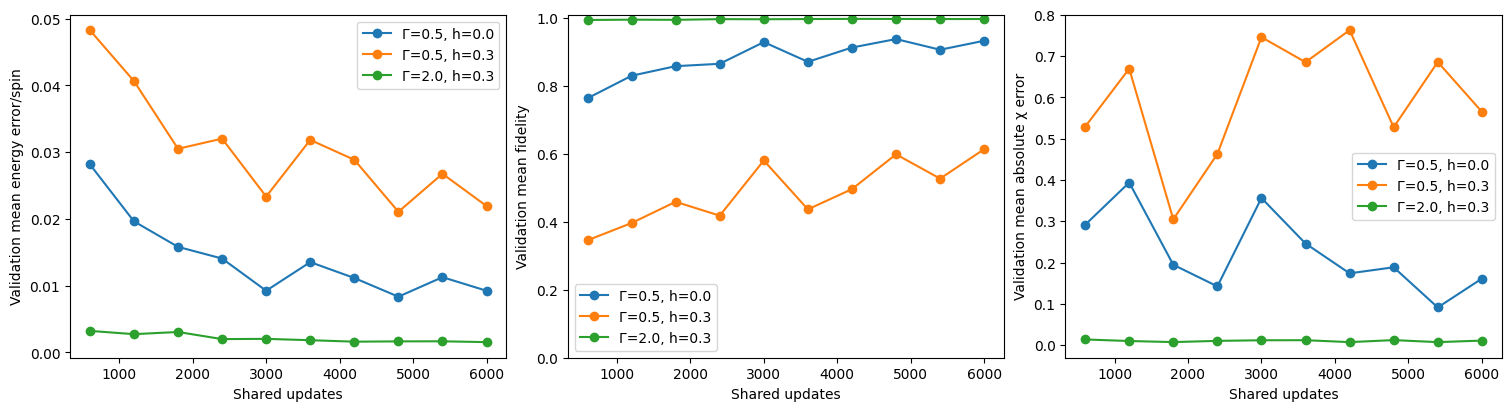

In [4]:
fig,axes=plt.subplots(1,3,figsize=(15,4),constrained_layout=True)
for gamma,h in ((.5,0.),(.5,.3),(2.,.3)):
    points=[]
    for v in validations:
        selected=[r for r in v['rows'] if r['L']==2 and r['sample_id']>=10000 and (r['gamma'],r['h'])==(gamma,h)]
        if selected:
            step=int(v['checkpoint'].split('step')[1].split('.')[0])
            points.append((step,np.mean([r['energy_error_per_spin'] for r in selected]),np.mean([r['fidelity'] for r in selected]),np.mean([abs(r['chi_connected']-r['exact_chi']) for r in selected])))
    if points:
        x,e,f,c=np.array(points).T
        axes[0].plot(x,e,'o-',label=f'Γ={gamma}, h={h}')
        axes[1].plot(x,f,'o-',label=f'Γ={gamma}, h={h}')
        axes[2].plot(x,c,'o-',label=f'Γ={gamma}, h={h}')
axes[0].set(xlabel='Shared updates',ylabel='Validation mean energy error/spin')
axes[1].set(xlabel='Shared updates',ylabel='Validation mean fidelity',ylim=(0,1.01))
axes[2].set(xlabel='Shared updates',ylabel='Validation mean absolute χ error')
for ax in axes:
    if ax.lines: ax.legend()
fig.savefig(RESULTS/'validation.png',dpi=180)
fig.savefig(RESULTS/'validation.pdf')
plt.show()


In [5]:
table=['| Spins | Disorder | Γ | h | Energy/spin ± SE | Variance/spin | Connected χ ± SE |','|---:|---:|---:|---:|---:|---:|---:|']
for r in rows:
    if r['L']>2:
        s=r['sampled'];N=3*r['L']**2
        table.append(f"| {N} | {r['sample_id']} | {r['gamma']} | {r['h']} | {s['energy']['mean']/N:.6f} ± {s['energy']['se']/N:.6f} | {s['local_energy_variance']/N:.6g} | {s['chi_connected']['mean']:.6f} ± {s['chi_connected']['se']:.6f} |")
display(Markdown('\n'.join(table)))


| Spins | Disorder | Γ | h | Energy/spin ± SE | Variance/spin | Connected χ ± SE |
|---:|---:|---:|---:|---:|---:|---:|
| 48 | 0 | 0.5 | 0.0 | -1.045361 ± 0.000706 | 0.0846236 | 4.105469 ± 0.128593 |
| 48 | 0 | 0.5 | 0.3 | -1.062438 ± 0.000902 | 0.0767959 | 1.897013 ± 0.079044 |
| 48 | 0 | 2.0 | 0.3 | -2.221917 ± 0.000741 | 0.0327043 | 1.222697 ± 0.040358 |
| 48 | 10000 | 0.5 | 0.0 | -1.071832 ± 0.000839 | 0.0919852 | 3.401693 ± 0.125501 |
| 48 | 10000 | 0.5 | 0.3 | -1.094234 ± 0.001038 | 0.0824792 | 1.670247 ± 0.048676 |
| 48 | 10000 | 2.0 | 0.3 | -2.240385 ± 0.000606 | 0.0330223 | 1.151693 ± 0.038519 |
| 48 | 10001 | 0.5 | 0.0 | -1.021777 ± 0.000894 | 0.0477763 | 3.000407 ± 0.102086 |
| 48 | 10001 | 0.5 | 0.3 | -1.037913 ± 0.001173 | 0.0817554 | 1.840658 ± 0.080817 |
| 48 | 10001 | 2.0 | 0.3 | -2.226014 ± 0.000389 | 0.0223566 | 1.227498 ± 0.038902 |
| 108 | 0 | 0.5 | 0.0 | -1.072722 ± 0.000514 | 0.0874729 | 4.078432 ± 0.147512 |
| 108 | 0 | 0.5 | 0.3 | -1.092987 ± 0.001054 | 0.089101 | 2.226201 ± 0.069432 |
| 108 | 0 | 2.0 | 0.3 | -2.238185 ± 0.000348 | 0.0306308 | 1.172888 ± 0.036101 |
| 108 | 10000 | 0.5 | 0.0 | -1.056624 ± 0.000657 | 0.0822699 | 3.545374 ± 0.152880 |
| 108 | 10000 | 0.5 | 0.3 | -1.070325 ± 0.000605 | 0.0833251 | 1.906648 ± 0.079053 |
| 108 | 10000 | 2.0 | 0.3 | -2.232504 ± 0.000283 | 0.0325634 | 1.135561 ± 0.036789 |
| 108 | 10001 | 0.5 | 0.0 | -1.038091 ± 0.000692 | 0.0706467 | 4.209871 ± 0.153586 |
| 108 | 10001 | 0.5 | 0.3 | -1.050693 ± 0.000446 | 0.0683535 | 2.231355 ± 0.076464 |
| 108 | 10001 | 2.0 | 0.3 | -2.224812 ± 0.000399 | 0.0274431 | 1.175492 ± 0.026482 |
| 192 | 0 | 0.5 | 0.0 | -1.044634 ± 0.000517 | 0.0676698 | 2.987722 ± 0.117324 |
| 192 | 0 | 0.5 | 0.3 | -1.054143 ± 0.000352 | 0.0688515 | 2.876729 ± 0.089468 |
| 192 | 0 | 2.0 | 0.3 | -2.225536 ± 0.000253 | 0.0285129 | 1.119548 ± 0.045220 |
| 192 | 10000 | 0.5 | 0.0 | -1.025591 ± 0.000473 | 0.0645579 | 3.679789 ± 0.149825 |
| 192 | 10000 | 0.5 | 0.3 | -1.040256 ± 0.000368 | 0.0699047 | 2.363810 ± 0.090482 |
| 192 | 10000 | 2.0 | 0.3 | -2.217125 ± 0.000304 | 0.0261593 | 1.197378 ± 0.039193 |
| 192 | 10001 | 0.5 | 0.0 | -1.030603 ± 0.000336 | 0.0655481 | 3.397196 ± 0.121765 |
| 192 | 10001 | 0.5 | 0.3 | -1.044229 ± 0.000350 | 0.0759477 | 2.647288 ± 0.107882 |
| 192 | 10001 | 2.0 | 0.3 | -2.220544 ± 0.000221 | 0.0283249 | 1.133494 ± 0.037095 |

In [6]:
table=['| Spins | Disorder | Γ | χ − Nq² at h=0 | Paired batch SE |',
       '|---:|---:|---:|---:|---:|']
for r in rows:
    if r['L']>2 and r['h']==0:
        s=r['sampled'];N=3*r['L']**2
        differences=np.array(s['chi_connected']['batches'])-N*np.array(s['q2']['batches'])
        se=differences.std(ddof=1)/np.sqrt(len(differences))
        table.append(f"| {N} | {r['sample_id']} | {r['gamma']} | {differences.mean():.6f} | {se:.6f} |")
display(Markdown('For an exactly spin-flip symmetric guide, χ = Nq². The independent-replica estimators fluctuate; the paired batch uncertainty below includes their covariance.'))
display(Markdown('\n'.join(table)))
auditpath=RESULTS/'symmetry_audit.json'
if auditpath.exists() and evaluation:
    audit=json.loads(auditpath.read_text())
    assert audit['sha256']==evaluation['sha256'] and audit['passed']
    largest=max(r['max_translation_logp_error'] for r in audit['rows'])
    display(Markdown(f'**Final checkpoint symmetry audit passed:** largest translation log-probability difference {largest:.3g}; precision {audit["precision"]}. L2 is enumerated; larger-size checks use sampled configurations.'))


For an exactly spin-flip symmetric guide, χ = Nq². The independent-replica estimators fluctuate; the paired batch uncertainty below includes their covariance.

| Spins | Disorder | Γ | χ − Nq² at h=0 | Paired batch SE |
|---:|---:|---:|---:|---:|
| 48 | 0 | 0.5 | 0.253174 | 0.147997 |
| 48 | 10000 | 0.5 | -0.110107 | 0.152225 |
| 48 | 10001 | 0.5 | -0.301554 | 0.143039 |
| 108 | 0 | 0.5 | -0.171495 | 0.212824 |
| 108 | 10000 | 0.5 | 0.058377 | 0.165811 |
| 108 | 10001 | 0.5 | -0.006456 | 0.168290 |
| 192 | 0 | 0.5 | -0.228882 | 0.173427 |
| 192 | 10000 | 0.5 | -0.165253 | 0.200061 |
| 192 | 10001 | 0.5 | 0.037567 | 0.187950 |

**Final checkpoint symmetry audit passed:** largest translation log-probability difference 0; precision float64. L2 is enumerated; larger-size checks use sampled configurations.

## Low-field physics: spectral diagnosis

For a normalized guide, write ψ = Σₙ cₙ|n⟩. Its energy excess is
E−E₀ = Σₙ>₀ |cₙ|²(Eₙ−E₀), whereas fidelity is |c₀|². Thus small gaps
make energy a weak discriminator of the state and its correlations. The bound
1−F ≤ (E−E₀)/Δ uses total energy excess, not error per spin. At h=0 this
guide is exactly even, so the relevant Δ is the next even-sector gap; the
lower odd-sector level cannot carry guide weight.

The following frozen-checkpoint diagnostics use exact 12-spin spectra. They
identify finite-size competition between low-energy states; they do not establish
a thermodynamic phase or an exponentially small tunnelling gap. Spectral weight
is a wavefunction overlap, not a probability of occupying a classical basin.


In [7]:
spectral_paths=sorted(RESULTS.glob('low_field_spectrum_*.json'))
for spectral_path in spectral_paths:
    diagnostic=json.loads(spectral_path.read_text())
    import hashlib
    frozen=RESULTS/diagnostic['checkpoint']
    assert hashlib.sha256(frozen.read_bytes()).hexdigest()==diagnostic['sha256']
    display(Markdown(f"**Spectral audit: update {diagnostic['step']}**, checkpoint `{diagnostic['checkpoint']}`."))
    table=['| Disorder | Γ | h | Accessible gap | Total energy excess / gap | Ground weight | First excited weight | First 16 weight |',
           '|---:|---:|---:|---:|---:|---:|---:|---:|']
    for r in diagnostic['rows']:
        table.append(f"| {r['sample_id']} | {r['gamma']} | {r['h']} | {r['accessible_gap']:.6f} | {r['energy_excess_over_gap']:.3f} | {r['ground_fidelity']:.6f} | {r['spectral_weights'][1]:.6f} | {r['first_16_weight']:.6f} |")
    display(Markdown('\n'.join(table)))
if not spectral_paths:
    display(Markdown('No spectral audit has been recorded for this campaign.'))


**Spectral audit: update 6000**, checkpoint `shared_symmetric_alibi__L02-04-06-08__seed501__final.pt`.

| Disorder | Γ | h | Accessible gap | Total energy excess / gap | Ground weight | First excited weight | First 16 weight |
|---:|---:|---:|---:|---:|---:|---:|---:|
| 10000 | 0.5 | 0.0 | 0.224844 | 0.390 | 0.965823 | 0.000736 | 0.980605 |
| 10000 | 0.5 | 0.3 | 0.297950 | 0.870 | 0.561591 | 0.305575 | 0.969939 |
| 10000 | 2.0 | 0.3 | 2.098484 | 0.010 | 0.996696 | 0.000069 | 0.997789 |
| 10001 | 0.5 | 0.0 | 0.354349 | 0.378 | 0.900134 | 0.008036 | 0.978726 |
| 10001 | 0.5 | 0.3 | 0.146645 | 1.820 | 0.666248 | 0.002169 | 0.951350 |
| 10001 | 2.0 | 0.3 | 2.218306 | 0.007 | 0.997225 | 0.000284 | 0.999068 |

**Spectral audit: update 2400**, checkpoint `shared_symmetric_alibi__step002400.pt`.

| Disorder | Γ | h | Accessible gap | Total energy excess / gap | Ground weight | First excited weight | First 16 weight |
|---:|---:|---:|---:|---:|---:|---:|---:|
| 10000 | 0.5 | 0.0 | 0.224844 | 0.482 | 0.951199 | 0.007786 | 0.977300 |
| 10000 | 0.5 | 0.3 | 0.297950 | 1.402 | 0.217965 | 0.619812 | 0.960382 |
| 10000 | 2.0 | 0.3 | 2.098484 | 0.013 | 0.996270 | 0.000267 | 0.997168 |
| 10001 | 0.5 | 0.0 | 0.354349 | 0.646 | 0.779060 | 0.012049 | 0.972490 |
| 10001 | 0.5 | 0.3 | 0.146645 | 2.391 | 0.618409 | 0.010262 | 0.938598 |
| 10001 | 2.0 | 0.3 | 2.218306 | 0.009 | 0.996802 | 0.000018 | 0.998436 |

**Final frozen-guide correlations and field response (L2)**

| ID | Γ | h | Fidelity | RMS connected-C error | Max connected-C error | Absolute Δχ |
|---:|---:|---:|---:|---:|---:|---:|
| 10000 | 0.5 | 0.0 | 0.965823 | 0.053751 | 0.131242 | 0.089539 |
| 10000 | 0.5 | 0.3 | 0.561591 | 0.207331 | 0.632000 | 1.105488 |
| 10000 | 2.0 | 0.3 | 0.996696 | 0.013833 | 0.062035 | 0.012831 |
| 10000 | 0.4 | 0.15 | 0.467715 | 0.212626 | 0.537889 | 1.118906 |
| 10000 | 0.7 | 0.15 | 0.935763 | 0.057287 | 0.162668 | 0.395030 |
| 10000 | 1.0 | 0.15 | 0.985734 | 0.029020 | 0.068389 | 0.031745 |
| 10000 | 1.5 | 0.15 | 0.993231 | 0.022061 | 0.087678 | 0.031017 |
| 10001 | 0.5 | 0.0 | 0.900134 | 0.166173 | 0.366998 | 0.232777 |
| 10001 | 0.5 | 0.3 | 0.666248 | 0.108857 | 0.319720 | 0.025438 |
| 10001 | 2.0 | 0.3 | 0.997225 | 0.010795 | 0.027599 | 0.009500 |
| 10001 | 0.4 | 0.15 | 0.598089 | 0.084963 | 0.171830 | 0.235266 |
| 10001 | 0.7 | 0.15 | 0.924099 | 0.075020 | 0.187748 | 0.157828 |
| 10001 | 1.0 | 0.15 | 0.979697 | 0.040219 | 0.112941 | 0.061129 |
| 10001 | 1.5 | 0.15 | 0.995117 | 0.018076 | 0.043591 | 0.022745 |

**Exact 12-spin projection reference**

| ID | Γ | h | Initial F | Final τ | Final F | Final C RMS error |
|---:|---:|---:|---:|---:|---:|---:|
| 10000 | 0.5 | 0.0 | 0.965823 | 16.0 | 0.99999943 | 0.000614175 |
| 10000 | 0.5 | 0.3 | 0.561591 | 16.0 | 0.99996062 | 0.00187026 |
| 10000 | 2.0 | 0.3 | 0.996696 | 16.0 | 1.00000000 | 6.36449e-15 |
| 10001 | 0.5 | 0.0 | 0.900134 | 16.0 | 0.99999989 | 0.000247053 |
| 10001 | 0.5 | 0.3 | 0.666248 | 16.0 | 0.99987093 | 0.00187165 |
| 10001 | 2.0 | 0.3 | 0.997225 | 16.0 | 1.00000000 | 3.28446e-15 |

Normalized exp[−τ(H−E₀)]ψ on all 4096 configurations gives a finite-size imaginary-time target. Walker population, branching and forward-time convergence remain to be established independently.

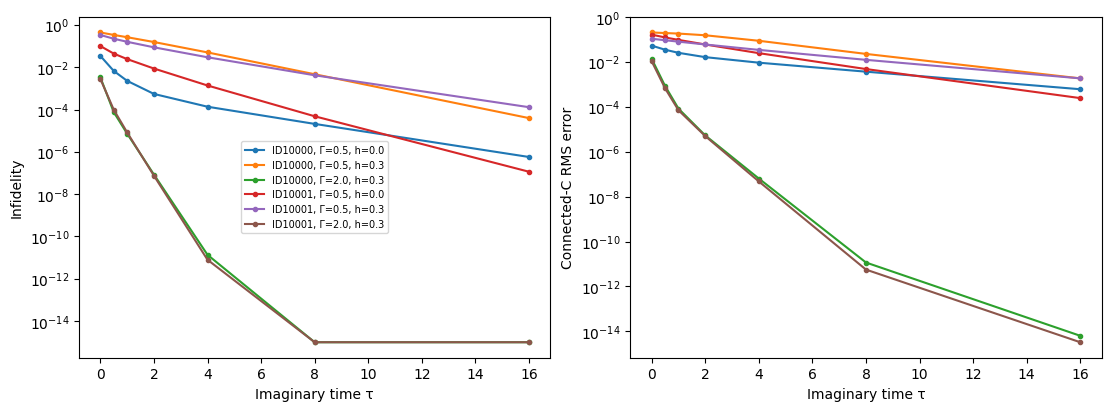

In [8]:
path=RESULTS/'correlation_comparison.json'
if path.exists():
    diagnostic=json.loads(path.read_text())
    table=['| ID | Γ | h | Fidelity | RMS connected-C error | Max connected-C error | Absolute Δχ |','|---:|---:|---:|---:|---:|---:|---:|']
    for run in diagnostic['runs']:
        assert hashlib.sha256(Path(run['checkpoint']).read_bytes()).hexdigest()==run['sha256']
        for v in run['rows']:
            table.append(f"| {v['sample_id']} | {v['gamma']} | {v['h']} | {v['fidelity']:.6f} | {v['connected_correlation_rms_error']:.6f} | {v['connected_correlation_max_error']:.6f} | {abs(v['chi_connected']-v['exact_chi']):.6f} |")
    display(Markdown('**Final frozen-guide correlations and field response (L2)**\n\n'+'\n'.join(table)))
path=RESULTS/'exact_projection_final.json'
if path.exists():
    diagnostic=json.loads(path.read_text())
    assert hashlib.sha256(Path(diagnostic['checkpoint']).read_bytes()).hexdigest()==diagnostic['sha256']
    table=['| ID | Γ | h | Initial F | Final τ | Final F | Final C RMS error |','|---:|---:|---:|---:|---:|---:|---:|']
    fig,axes=plt.subplots(1,2,figsize=(11,4),constrained_layout=True)
    for v in diagnostic['rows']:
        first,last=v['trajectory'][0],v['trajectory'][-1]
        table.append(f"| {v['sample_id']} | {v['gamma']} | {v['h']} | {first['fidelity']:.6f} | {last['tau']} | {last['fidelity']:.8f} | {last['connected_correlation_rms_error']:.6g} |")
        label=f"ID{v['sample_id']}, Γ={v['gamma']}, h={v['h']}"
        times=[q['tau'] for q in v['trajectory']]
        axes[0].semilogy(times,[max(1e-15,1-q['fidelity']) for q in v['trajectory']],'.-',label=label)
        axes[1].semilogy(times,[max(1e-15,q['connected_correlation_rms_error']) for q in v['trajectory']],'.-',label=label)
    display(Markdown('**Exact 12-spin projection reference**\n\n'+'\n'.join(table)))
    display(Markdown('Normalized exp[−τ(H−E₀)]ψ on all 4096 configurations gives a finite-size imaginary-time target. Walker population, branching and forward-time convergence remain to be established independently.'))
    axes[0].set_ylabel('Infidelity'); axes[1].set_ylabel('Connected-C RMS error')
    for ax in axes: ax.set_xlabel('Imaginary time τ')
    axes[0].legend(fontsize=7)
    fig.savefig(RESULTS/'exact_projection.png',dpi=180)
    fig.savefig(RESULTS/'exact_projection.pdf')
    plt.show()


## Comparison and decision

Symmetry enforcement is a mathematical property, not an accuracy certificate.
At zero field, connected χ must equal Nq² because local magnetizations vanish;
the value can still be inaccurate if even-sector correlations are wrong.
Compare held-out energy errors and fidelities to the previous checkpoint,
retain all training outcomes, and inspect low-field versus high-field behavior.
All larger-size results use identical frozen weights; no specialist adaptation
occurs during evaluation.


In [9]:
ROOT=Path.cwd()
if not (ROOT/'code/transformer_qmc').exists(): ROOT=ROOT.parent
oldpath=ROOT/'data/kagome/transformer_af_shared_accuracy_v1/symmetry_diagnostics.json'
if oldpath.exists() and rows:
    old=json.loads(oldpath.read_text())
    pairs=[]
    for r in rows:
        if r['L']==2 and r['sample_id'] in range(2,10) and (r['gamma'],r['h'])==(.5,.3):
            prior=next(x for x in old['rows'] if (x['sample_id'],x['gamma'],x['h'])==(r['sample_id'],r['gamma'],r['h']))['states']['original']
            pairs.append((r['sample_id'],prior['energy_error_per_spin'],r['energy_error_per_spin'],prior['fidelity'],r['fidelity']))
    table=['| Held-out disorder | Previous error/spin | New error/spin | Previous fidelity | New fidelity |','|---:|---:|---:|---:|---:|']
    for s,a,b,c,d in pairs:
        table.append(f'| {s} | {a:.6f} | {b:.6f} | {c:.6f} | {d:.6f} |')
    display(Markdown('\n'.join(table)))
    if pairs:
        values=np.array(pairs)
        display(Markdown(f"**Mean retrospective held-out error/spin:** {values[:,1].mean():.6f} → {values[:,2].mean():.6f}."))


| Held-out disorder | Previous error/spin | New error/spin | Previous fidelity | New fidelity |
|---:|---:|---:|---:|---:|
| 2 | 0.558849 | 0.033494 | 0.000877 | 0.303434 |
| 3 | 0.131194 | 0.018519 | 0.134828 | 0.745869 |
| 4 | 0.200323 | 0.018820 | 0.023723 | 0.313153 |
| 5 | 0.149291 | 0.022766 | 0.049578 | 0.636059 |
| 6 | 0.455526 | 0.088528 | 0.140348 | 0.230257 |
| 7 | 0.147016 | 0.019087 | 0.000016 | 0.888137 |
| 8 | 0.336602 | 0.023602 | 0.035434 | 0.637224 |
| 9 | 0.149955 | 0.032191 | 0.421885 | 0.078155 |

**Mean retrospective held-out error/spin:** 0.266095 → 0.032126.